# Re-batching partiendo del deposito real

**Pregunta.** Cuanto baja la caminata si, ademas de decidir donde va cada SKU, se decide que ordenes
se recogen juntas, partiendo del deposito real; segun el plan y la ventana; y cuanto espera una orden
a cambio.

**Que se compara.** Cuatro planes (el vigente y tres calculados) con cinco ventanas de re-batching,
todos con el regimen de simulacion del proyecto: el deposito arranca como esta al corte, el plan entra
por las mudanzas con la regla `plan_aisle`, y los batches se arman con el pasillo que cada SKU tiene en
ese momento. Las diferencias son contra **hoy**: el deposito real, con reposiciones como en los datos
y batches FIFO.

Es la version, con el regimen vigente, de `old_base/04_rebatching`, que aplicaba el plan entero en el
corte.

**Contenido.**
0. Configuracion: el modelo y todos los parametros.
1. Datos y tres hechos que se usan despues.
2. El recorrido en S.
3. Los planes.
4. El re-batching: el problema, el algoritmo y que cambia partiendo del deposito real.
5. Cuanto espera una orden.
6. Como se simula.
7. Resultados en `medium`.
8. Otros depositos.
9. Lectura.

## 0. Configuracion

| componente | parametro | valor | que hace |
|---|---|---|---|
| datos | deposito | `medium`; la seccion 8 repite con `small` y `medium-alpha-1.3` | carpeta de `data/v2`; `big` esta en `02_combinatoria`, bloque A |
| particion | fraccion de test | 0,4 | los batches se ordenan por la hora de su primera linea; el ultimo 40% es test (72 dias, unas 10 semanas) |
| instancia | demanda $f_i$ | `pick_lines` | fraccion de las lineas de train que piden el SKU $i$ |
| instancia | costo $c_l$ | distancia caminando de la bay al dock | ordena las ubicaciones |
| ruteo | recorrido | `s_shape` | S estricto (seccion 2) |
| slotting | planes | vigente, `demand_greedy`, `aisle_fill`, `merchant_aisle_fill` | seccion 3; ninguno tiene parametros |
| batching | ordenes por batch | 25 | como en los datos |
| batching | ventana $W$ | 1, 2, 4, 8, 16 | batches FIFO consecutivos que se re-arman juntos; 1 es FIFO |
| batching | pasadas de intercambio | 20 | tope de la mejora local (seccion 4) |
| simulacion | estado inicial | el deposito real al corte | |
| simulacion | reposicion | `plan_aisle`: si quedan unidades en el lugar; si el SKU se agoto, a su pasillo del plan | la regla del proyecto |
| referencia | hoy | deposito real, reposicion `random` (como en los datos), FIFO | todas las diferencias son contra hoy |
| referencia | techo | el plan aplicado de una vez, reposicion `home` | lo que daria el plan con el deposito reordenado el primer dia |
| medidas | promedio y final | caminata media por batch en todo el test y en los ultimos 14 dias | el final muestra hasta donde se llega |

In [1]:
import time
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abs_affinity_based_slotting.config import dataset_dir
from abs_affinity_based_slotting.data import WarehouseDataLoader, split_picking_events
from abs_affinity_based_slotting.demand import TopKFilter
from abs_affinity_based_slotting.slotting import build_full_instance, Assignment
from abs_affinity_based_slotting.methods import method_registry
from abs_affinity_based_slotting.simulation import (Simulator, split_replenishments, build_event_stream,
                                                    state_from_initial_stock, state_after_history, reslot_state,
                                                    HomePolicy, RandomStoragePolicy, PlanAislePolicy,
                                                    simulate_rolling, location_aisles)
from abs_affinity_based_slotting.batching import FifoBatching, AisleCoverBatching, orders_by_arrival, order_waits

pd.set_option("display.width", 180)

DATASET = "medium"
OTROS = ["small", "medium-alpha-1.3"]
TEST_SIZE = 0.4
INSTANCIA = dict(demand_metric="pick_lines", affinity_metric="jaccard", cooccurrence_col="order_id",
                 affinity_filter=TopKFilter(k=10), normalize=True, pair_distance_model="aisle")
BATCH_SIZE = 25
VENTANAS = [1, 2, 4, 8, 16]
MAX_PASSES = 20
SEMILLA = 0
PLANES = ["vigente", "demand_greedy", "aisle_fill", "merchant_aisle_fill"]
COLORES = {"vigente": "#eda100", "demand_greedy": "#2a78d6", "aisle_fill": "#eb6834", "merchant_aisle_fill": "#1baf7a"}

## 1. Datos y tres hechos

`split_picking_events` deja el ultimo 40% de los batches como test; `build_full_instance` arma la
instancia con train; `state_after_history` da el deposito real al corte; `Simulator` camina cada batch
en S. Todo va en una funcion para repetirlo con otros depositos.

In [2]:
def preparar(nombre):
    # Datos, instancia, deposito real al corte, simulador en S y pasillo de cada ubicacion.
    ds = WarehouseDataLoader(dataset_dir("v2", nombre)).load_all()
    split = split_picking_events(ds.picking_events, test_size=TEST_SIZE)
    instance = build_full_instance(split.train, ds.initial_stock, ds.distances, coordinates=ds.coordinates, **INSTANCIA)
    replen_train, replen_test = split_replenishments(ds.replenishment_events, split.train, ds.initial_stock, split.cutoff)
    state0 = state_from_initial_stock(instance, ds.initial_stock)
    state_cut, _ = state_after_history(state0, build_event_stream(split.train, replen_train, instance), instance)
    sim = Simulator.from_tables(instance, ds.coordinates, routing="s_shape")
    inicio = ds.picking_events.groupby("batch_id")["timestamp"].min().sort_values()
    return SimpleNamespace(nombre=nombre, ds=ds, split=split, instance=instance, replen_test=replen_test,
                           state_cut=state_cut, sim=sim, costo=sim.routing.mask_costs(),
                           pasillo_de_ubicacion=location_aisles(sim, instance),
                           minutos_por_batch=float(inicio.diff().dt.total_seconds().median() / 60))


ctx = preparar(DATASET)
inst, test = ctx.instance, ctx.split.test
pd.Series({"pasillos": ctx.sim.routing.n_aisles, "SKUs": inst.n_skus, "merchants": len(set(inst.merchant_ids)),
           "batches de test": test["batch_id"].nunique(), "ordenes de test": test["order_id"].nunique(),
           "corte": ctx.split.cutoff}, name=DATASET).to_frame()

,medium
pasillos,8
SKUs,6912
merchants,50
batches de test,3258
ordenes de test,81450
corte,2026-04-19 14:24:22.733333


**Hecho 1:** cada orden tiene SKUs de un solo merchant.

In [3]:
print("merchants distintos por orden:", ctx.ds.picking_events.groupby("order_id")["merchant_account_id"].nunique().value_counts().to_dict())

merchants distintos por orden: {1: 203625}


**Hecho 2:** todos los batches tienen 25 ordenes y sale uno nuevo a ritmo constante. Los datos no traen la hora en que llega cada orden.

In [4]:
todo = ctx.ds.picking_events
print("ordenes por batch:", todo.groupby("batch_id")["order_id"].nunique().agg(["min", "max"]).tolist())
print(f"un batch cada {ctx.minutos_por_batch:.1f} minutos (mediana)")

ordenes por batch: [25, 25]
un batch cada 32.0 minutos (mediana)


**Hecho 3:** al corte, cada SKU esta en exactamente una ubicacion.

In [5]:
print("ubicaciones por SKU al corte:", pd.Series([len(ctx.state_cut.locations_of(s)) for s in range(inst.n_skus)]).value_counts().to_dict())

ubicaciones por SKU al corte: {1: 6912}


## 2. El recorrido en S

El picker sale del dock, recorre entero cada pasillo con picks, alternando de ida y de vuelta, saltea los
que no tienen picks, y si recorrio una cantidad impar vuelve al frente por el ultimo. Para los pasillos
visitados $S = \{a_1 < \dots < a_m\}$:

$$R_S(S) = d_0(a_1) + m\,L + (x_{a_m} - x_{a_1}) + [\,m \text{ impar}\,]\,L + d_0(a_m),
\qquad d_0(a) = |x_a - x_{\text{dock}}| + (y_0 - y_{\text{dock}}),$$

con $L$ el largo de un pasillo, $x_a$ su coordenada lateral y $d_0(a)$ la distancia del dock al frente
del pasillo $a$. **El largo depende solo de que pasillos se visitan**, no de donde esta cada pick dentro
del pasillo. Se calcula una vez para cada conjunto de pasillos.

In [6]:
r = ctx.sim.routing
d0 = lambda a: abs(r.aisle_x[a] - r.dock_xy[0]) + (r.front_y - r.dock_xy[1])     # a = 0 es el pasillo 1
L = r.aisle_length
print(f"{r.n_aisles} pasillos, L = {L:.0f} pulgadas")
print("pasillo 1 a mano:", d0(0) + L + L + d0(0), "| paquete:", r.distance_of_aisles([0]))
print("pasillos 1 y 2 a mano:", d0(0) + 2 * L + (r.aisle_x[1] - r.aisle_x[0]) + d0(1), "| paquete:", r.distance_of_aisles([0, 1]))
RS = lambda pasillos_1: r.distance_of_aisles([a - 1 for a in pasillos_1])          # pasillos numerados desde 1
print("todos los pasillos:", ctx.costo[-1])

8 pasillos, L = 1776 pulgadas
pasillo 1 a mano: 4480.0 | paquete: 4480.0
pasillos 1 y 2 a mano: 4864.0 | paquete: 4864.0
todos los pasillos: 17824.0


## 3. Los planes

| plan | orden de los SKUs | orden de las ubicaciones | por que esta |
|---|---|---|---|
| vigente | donde estan al corte | | con la regla, cada SKU que se agota vuelve a su pasillo actual |
| `demand_greedy` | $f_i$ descendente | distancia al dock ascendente | lo mas pedido, lo mas cerca |
| `aisle_fill` | $f_i$ descendente | por pasillo, del mas cercano al dock al mas lejano, y dentro por distancia | concentra lo mas pedido en pocos pasillos |
| `merchant_aisle_fill` | merchants por demanda total, y dentro de cada merchant por $f_i$ | igual que `aisle_fill` | cada merchant en un pasillo: por el hecho 1, cada orden en un pasillo |

Cada plan le da a cada SKU un pasillo; la regla de reposicion lo lleva ahi cuando se agota. Pasillos
que toca en promedio una orden de test con los SKUs donde estan al corte y con cada plan completo:

In [7]:
def planes_de(c):
    # Los cuatro planes y el pasillo que cada uno le da a cada SKU.
    i, coords = c.instance, c.ds.coordinates
    vigente = Assignment({i.sku_id(k): i.location_id(c.state_cut.primary_location(k)) for k in range(i.n_skus)})
    planes = {"vigente": vigente,
              "demand_greedy": method_registry.get("demand_greedy")().solve(i),
              "aisle_fill": method_registry.get("aisle_fill")(coords).solve(i),
              "merchant_aisle_fill": method_registry.get("merchant_aisle_fill")(coords).solve(i)}
    pasillos = {}
    for nombre, plan in planes.items():
        loc = np.array([i.location_index(plan.location_of(k)) for k in i.sku_ids])
        pasillos[nombre] = pd.Series(c.pasillo_de_ubicacion[loc], index=i.sku_ids)
    return planes, pasillos


planes, pasillos = planes_de(ctx)
lineas = test[["order_id", "sku"]].drop_duplicates()
pd.Series({nombre: lineas.assign(a=lineas["sku"].map(sa)).groupby("order_id")["a"].nunique().mean()
           for nombre, sa in pasillos.items()}, name="pasillos por orden").round(2).to_frame()

,pasillos por orden
vigente,2.94
demand_greedy,2.40
aisle_fill,1.94
merchant_aisle_fill,1.03


## 4. El re-batching

### 4.1 El problema

En vez de cerrar un batch apenas hay 25 ordenes, se esperan $25\,W$ ordenes consecutivas (un **pool**)
y se reparten en $W$ batches de 25. Para cada orden $o$, $A(o)$ es el conjunto de pasillos donde estan
sus SKUs; un batch entra a la union de los $A(o)$ de sus ordenes y camina $R_S$ de esa union.

**Variables.** $z_{ok} = 1$ si la orden $o$ va al batch $k$.

$$
\begin{aligned}
\min_{z}\quad & \sum_{k=1}^{W} R_S\Big(\bigcup_{o \,:\, z_{ok} = 1} A(o)\Big)
    && \text{(caminata total del pool)} \\
\text{s.a.}\quad & \sum_{k} z_{ok} = 1 \;\; \forall o, \qquad \sum_{o} z_{ok} = 25 \;\; \forall k, \qquad z_{ok} \in \{0, 1\}.
\end{aligned}
$$

### 4.2 El algoritmo (`AisleCoverBatching`)

1. **Construir.** Se abre un batch con la orden libre que sola camina mas, $\arg\max_o R_S(A(o))$, y se
   le agrega en cada paso la orden libre que menos aumenta la caminata del batch,
   $\Delta(o \mid M) = R_S(M \cup A(o)) - R_S(M)$, hasta 25. Se repite con las que quedan.
2. **Intercambiar.** Para cada orden se busca el intercambio con una orden de otro batch que mas baja la
   caminata total, y se hace si la baja. Se repite hasta una pasada sin cambios o 20 pasadas. Termina en
   un optimo local; no hay garantia de optimo global.

Parametros: 25 ordenes por batch, la ventana $W$ y el tope de 20 pasadas.

### 4.3 Que cambia partiendo del deposito real

$A(o)$ sale de donde estan los SKUs **en el momento de armar el pool**. Al empezar el test eso es el
deposito real; a medida que la regla muda SKUs a su pasillo del plan, $A(o)$ se parece cada vez mas al
del plan. Por eso la simulacion arma los batches pool por pool (seccion 6), y el mismo re-batching rinde
poco al principio y cada vez mas despues.

El mismo pool, las primeras 100 ordenes de test, armado en FIFO y con re-batching de ventana 4, con los
SKUs donde estan al corte y con los SKUs donde los pone el plan ganador:

In [8]:
pool = orders_by_arrival(test)[:4 * BATCH_SIZE]
lineas_pool = test[test["order_id"].isin(pool)]


def caminata_del_pool(sku_pasillo, ventana):
    # Caminata total del pool con los SKUs en esos pasillos, y pasillos de cada batch.
    armado = AisleCoverBatching(sku_pasillo, ctx.costo, batch_size=BATCH_SIZE, window=ventana,
                                max_passes=MAX_PASSES).make_batches(lineas_pool)
    g = armado.assign(a=armado["sku"].map(sku_pasillo)).groupby("batch_id")["a"]
    return g.apply(lambda x: r.distance_of_aisles(x.to_numpy())).sum(), g.nunique().tolist()


filas = []
for nombre, sa in [("deposito real al corte", pasillos["vigente"]), ("plan merchant_aisle_fill completo", pasillos["merchant_aisle_fill"])]:
    por_orden = lineas_pool.assign(a=lineas_pool["sku"].map(sa)).groupby("order_id")["a"].nunique()
    fifo, p_fifo = caminata_del_pool(sa, 1)
    rebatch, p_reb = caminata_del_pool(sa, 4)
    filas.append({"SKUs": nombre, "pasillos por orden": round(por_orden.mean(), 2),
                  "FIFO: caminata del pool": fifo, "FIFO: pasillos de cada batch": p_fifo,
                  "W=4: caminata del pool": rebatch, "W=4: pasillos de cada batch": p_reb,
                  "W=4 vs FIFO (%)": round(100 * (rebatch / fifo - 1), 1)})
pd.DataFrame(filas).set_index("SKUs").T

SKUs,deposito real al corte,plan merchant_aisle_fill completo
pasillos por orden,2.96,1.02
FIFO: caminata del pool,71296.0,70528.0
FIFO: pasillos de cada batch,"[8, 8, 8, 8]","[7, 8, 7, 8]"
W=4: caminata del pool,64192.0,37792.0
W=4: pasillos de cada batch,"[6, 6, 8, 8]","[4, 2, 4, 4]"
W=4 vs FIFO (%),-10.0,-46.4


Con los SKUs donde estan al corte, cada orden del pool toca casi 3 pasillos (2,96), asi que no hay
ordenes que se puedan juntar sin abrir pasillos: el re-batching solo baja la caminata del pool un 10%
(los batches pasan de entrar a 8 pasillos a entrar a 6, 6, 8 y 8). Con los SKUs donde los pone el plan
ganador, cada orden toca un pasillo (1,02) y el mismo re-batching baja un 46,4% (batches de 4, 2, 4 y 4
pasillos). En FIFO las dos versiones caminan casi lo mismo: el orden del deposito solo se aprovecha si
los batches se arman por pasillo, y el re-batching rinde tanto como el plan haya entrado.

## 5. Cuanto espera una orden

Los datos no traen la hora de llegada de cada orden (hecho 2), asi que se fija una regla: las ordenes
llegan en el orden de la FIFO y parejas, 25 por franja (el tiempo entre dos batches de los datos); un
pool se completa cuando llega su ultima orden, y desde ahi sus $W$ batches salen de a uno por franja,
primero el que tiene la orden mas vieja. Para la orden que llega en el lugar $r$ del pool $p$, en un
batch que sale en el turno $t$:
$$\text{espera} = \frac{r_{\max}(p) + 1}{25} + t - \frac{r}{25} \quad \text{franjas}.$$
La espera media no depende del plan.

In [9]:
esperas = {}
for w in VENTANAS:
    armado = AisleCoverBatching(pasillos["merchant_aisle_fill"], ctx.costo, batch_size=BATCH_SIZE, window=w,
                                max_passes=0).make_batches(test)
    e = order_waits(armado, w) * ctx.minutos_por_batch
    esperas[w] = {"espera media (min)": e.mean(), "espera maxima (min)": e.max()}
pd.DataFrame(esperas).round(0)

,1,2,4,8,16
espera media (min),17.0,49.0,113.0,241.0,496.0
espera maxima (min),32.0,95.0,218.0,468.0,764.0


## 6. Como se simula

Cada corrida simula el test entero, con las lineas de picking y las reposiciones de los datos:

- **regla**: deposito real al corte; reposicion `plan_aisle` con el plan; batches pool por pool con el
  pasillo actual de cada SKU (`simulate_rolling`): antes de cada pool se leen los pasillos, se re-arma el
  pool y se simulan sus batches y las reposiciones hasta su ultima linea;
- **hoy**: igual, con reposicion `random` y sin plan;
- **techo**: el plan aplicado de una vez (`reslot_state`), reposicion `home` y todos los batches armados
  de una vez con los pasillos del plan.

Las medidas son la caminata media por batch en todo el test (promedio) y en los ultimos 14 dias
(final), y se registra semana a semana.

In [10]:
def correr(c, regimen, plan_nombre, ventana, planes, pasillos):
    # Una corrida: fila de resultados y registro por batch.
    t0 = time.time()
    plan = planes[plan_nombre]
    if regimen == "techo":
        armado = AisleCoverBatching(pasillos[plan_nombre], c.costo, batch_size=BATCH_SIZE, window=ventana,
                                    max_passes=MAX_PASSES).make_batches(c.split.test)
        res = c.sim.run(reslot_state(c.state_cut, plan, c.instance), build_event_stream(armado, c.replen_test, c.instance),
                        HomePolicy(), planned=plan, seed=SEMILLA)
        log, mudanzas = res.batch_log, res.n_relocations
    else:
        politica = RandomStoragePolicy() if regimen == "hoy" else PlanAislePolicy(c.pasillo_de_ubicacion)
        res = simulate_rolling(c.sim, c.instance, c.state_cut, c.split.test, c.replen_test, politica,
                               aisle_set_cost=c.costo, window=ventana, batch_size=BATCH_SIZE, max_passes=MAX_PASSES,
                               planned=plan, seed=SEMILLA)
        log, mudanzas = res.batch_log, res.n_relocations
    ultimos = log["timestamp"] >= log["timestamp"].max() - pd.Timedelta(days=14)
    return {"regimen": regimen, "plan": plan_nombre, "ventana": ventana,
            "promedio": log["distance"].mean(), "final": log.loc[ultimos, "distance"].mean(),
            "pasillos por batch": log["n_aisles"].mean(), "mudanzas": mudanzas,
            "segundos": round(time.time() - t0, 1)}, log

## 7. Resultados en `medium`

Los cuatro planes con la regla en las cinco ventanas, hoy en las cinco ventanas (re-batching sin plan),
y el techo de cada plan con ventanas 1, 4 y 16.

In [11]:
filas, logs = [], {}
for p in PLANES:
    for w in VENTANAS:
        fila, logs[("regla", p, w)] = correr(ctx, "regla", p, w, planes, pasillos)
        filas.append(fila)
for w in VENTANAS:
    fila, logs[("hoy", "vigente", w)] = correr(ctx, "hoy", "vigente", w, planes, pasillos)
    filas.append(fila)
for p in PLANES[1:]:
    for w in (1, 4, 16):
        fila, logs[("techo", p, w)] = correr(ctx, "techo", p, w, planes, pasillos)
        filas.append(fila)
res = pd.DataFrame(filas)
hoy = res.query("regimen == 'hoy' and ventana == 1").iloc[0]
res["promedio vs hoy (%)"] = 100 * (res["promedio"] / hoy["promedio"] - 1)
res["final vs hoy (%)"] = 100 * (res["final"] / hoy["final"] - 1)
print("hoy: promedio", round(hoy["promedio"]), "| final", round(hoy["final"]), "| segundos en total:", round(res["segundos"].sum()))

hoy: promedio 17824 | final 17824 | segundos en total: 11618


**Final** (ultimos 14 dias) contra hoy, con la regla, por plan y ventana; y hoy con re-batching:

In [12]:
tabla = pd.concat([res.query("regimen == 'regla'"), res.query("regimen == 'hoy'").assign(plan="hoy (sin plan)")])
tabla.pivot(index="plan", columns="ventana", values="final vs hoy (%)").loc[PLANES + ["hoy (sin plan)"]].round(1)

ventana,1,2,4,8,16
plan,,,,,
vigente,0.0,-1.7,-11.0,-15.1,-18.0
demand_greedy,-0.6,-11.1,-17.1,-21.7,-24.0
aisle_fill,-1.0,-10.5,-16.8,-19.9,-22.6
merchant_aisle_fill,-0.4,-13.8,-27.4,-34.1,-37.1
hoy (sin plan),0.0,-0.5,-4.2,-5.2,-5.0


**Promedio** de todo el test contra hoy, que incluye la transicion:

In [13]:
tabla.pivot(index="plan", columns="ventana", values="promedio vs hoy (%)").loc[PLANES + ["hoy (sin plan)"]].round(1)

ventana,1,2,4,8,16
plan,,,,,
vigente,0.0,-1.6,-10.8,-15.2,-17.8
demand_greedy,-0.3,-9.1,-13.7,-17.0,-18.6
aisle_fill,-0.4,-8.2,-12.7,-15.0,-16.7
merchant_aisle_fill,-0.2,-10.4,-21.5,-28.3,-31.1
hoy (sin plan),0.0,-0.7,-4.1,-5.1,-5.5


Pasillos visitados por batch, de 8:

In [14]:
tabla.pivot(index="plan", columns="ventana", values="pasillos por batch").loc[PLANES + ["hoy (sin plan)"]].round(2)

ventana,1,2,4,8,16
plan,,,,,
vigente,8.00,7.75,6.86,6.45,6.21
demand_greedy,7.86,6.93,6.43,6.07,5.88
aisle_fill,7.83,7.00,6.52,6.26,6.06
merchant_aisle_fill,7.92,6.87,5.78,5.14,4.84
hoy (sin plan),8.00,7.84,7.31,7.10,7.03


El **techo** de cada plan (aplicado de una vez), contra hoy:

In [15]:
res.query("regimen == 'techo'").pivot(index="plan", columns="ventana", values="promedio vs hoy (%)").round(1)

ventana,1,4,16
plan,,,
aisle_fill,-6.0,-32.7,-39.7
demand_greedy,-1.2,-22.4,-32.0
merchant_aisle_fill,-2.6,-47.1,-61.8


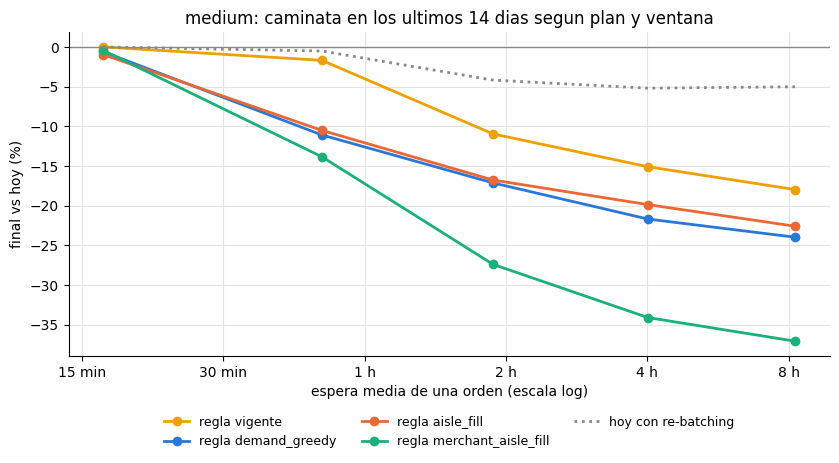

In [16]:
# Final contra hoy segun la espera media de una orden; cada punto es una ventana.
fig, ax = plt.subplots(figsize=(8.5, 4.8))
espera_h = pd.Series({w: v["espera media (min)"] / 60 for w, v in esperas.items()})
for p in PLANES:
    g = res.query("regimen == 'regla' and plan == @p").set_index("ventana").loc[VENTANAS]
    ax.plot(espera_h.loc[VENTANAS], g["final vs hoy (%)"], marker="o", ms=6, lw=2, color=COLORES[p], label=f"regla {p}")
g = res.query("regimen == 'hoy'").set_index("ventana").loc[VENTANAS]
ax.plot(espera_h.loc[VENTANAS], g["final vs hoy (%)"], ls=":", lw=2, color="#8a8a85", label="hoy con re-batching")
ax.set_xscale("log", base=2)
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8])
ax.set_xticklabels(["15 min", "30 min", "1 h", "2 h", "4 h", "8 h"])
ax.axhline(0, color="#8a8a85", lw=1)
ax.grid(True, color="#e5e4e0", lw=0.8)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("espera media de una orden (escala log)")
ax.set_ylabel("final vs hoy (%)")
ax.set_title(f"{DATASET}: caminata en los ultimos 14 dias segun plan y ventana")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

Semana a semana, con el plan `merchant_aisle_fill`, contra hoy, segun la ventana:

In [17]:
def por_semana(log):
    return log.groupby(log["timestamp"].dt.to_period("W"))["distance"].mean()


hoy_s = por_semana(logs[("hoy", "vigente", 1)])
pd.DataFrame({f"W={w}": (por_semana(logs[("regla", "merchant_aisle_fill", w)]) / hoy_s - 1) * 100 for w in VENTANAS}).round(1)

,W=1,W=2,W=4,W=8,W=16
timestamp,,,,,
2026-04-13/2026-04-19,0.0,-1.1,-4.3,-5.2,-6.0
2026-04-20/2026-04-26,-0.0,-4.0,-10.3,-14.3,-14.2
2026-04-27/2026-05-03,-0.0,-7.5,-14.6,-20.8,-24.1
2026-05-04/2026-05-10,-0.0,-9.2,-18.1,-26.0,-29.4
2026-05-11/2026-05-17,-0.1,-10.2,-20.6,-27.7,-31.3
2026-05-18/2026-05-24,-0.1,-10.2,-22.0,-29.9,-33.2
2026-05-25/2026-05-31,-0.2,-11.2,-24.0,-31.4,-33.9
2026-06-01/2026-06-07,-0.2,-11.8,-24.8,-31.8,-35.2
2026-06-08/2026-06-14,-0.2,-12.1,-25.7,-32.9,-36.2


**Hoy, re-armar los batches casi no sirve.** Sin plan, y con las reposiciones mudando SKUs al azar, el
re-batching baja el final un 4,2% con ventana 4 y a lo sumo un 5% con ventanas mas grandes: las ordenes
tocan casi 3 pasillos cada una (seccion 3).

**Con FIFO ningun plan gana mas de 1%,** porque un batch FIFO entra igual a casi todos los pasillos
(7,8 a 8 de 8).

**Con re-batching, el plan por merchant es el mejor en todas las ventanas.** Al final del test gana
13,8% con ventana 2, 27,4% con 4, 34,1% con 8 y 37,1% con 16. Con ventana 4, `demand_greedy` gana 17,1%
y `aisle_fill` 16,8%. Mantener el deposito vigente (la regla con el plan vigente, que devuelve cada SKU
que se agota a su pasillo actual en vez de mudarlo al azar) ya gana 11,0%: dejar de desordenar vale
algo por si solo.

**El promedio de todo el test es menor que el final**, porque incluye la transicion: con el plan por
merchant y ventana 4, 21,5% en promedio contra 27,4% al final. Semana a semana pasa de -4,3% en la
primera a -27,9% en la ultima, y con ventana 16 de -6,0% a -37,5%; hacia el final del test todavia baja,
aunque cada vez menos.

**El costo es la espera:** 17 minutos de media con FIFO, 49 con ventana 2, 113 con 4, 241 con 8 y 496
con 16 (seccion 5).

**Falta para el techo.** Con el plan por merchant aplicado de una vez se ganaria 47,1% con ventana 4 y
61,8% con 16. Aun asi, con ventana 4 la regla con el plan por merchant llega al final (-27,4%) mas lejos
que el techo de `demand_greedy` (-22,4%).

## 8. Otros depositos

`small` (4 pasillos, 4 merchants, un batch cada 240 minutos) y `medium-alpha-1.3` (`medium` con la
demanda mas concentrada). Los tres planes calculados con la regla en ventanas 1, 4 y 16, hoy con las
mismas ventanas, y el techo con ventana 4.

In [18]:
del logs
filas_o = []
for nombre in OTROS:
    c = preparar(nombre)
    pl, pa = planes_de(c)
    corridas = [("regla", p, w) for p in PLANES[1:] for w in (1, 4, 16)] + [("hoy", "vigente", w) for w in (1, 4, 16)]
    corridas += [("techo", p, 4) for p in PLANES[1:]]
    for regimen, p, w in corridas:
        fila, _ = correr(c, regimen, p, w, pl, pa)
        filas_o.append({"deposito": nombre, **fila})
    del c
otros = pd.DataFrame(filas_o)
base = otros.query("regimen == 'hoy' and ventana == 1").set_index("deposito")
otros["promedio vs hoy (%)"] = 100 * (otros["promedio"] / otros["deposito"].map(base["promedio"]) - 1)
otros["final vs hoy (%)"] = 100 * (otros["final"] / otros["deposito"].map(base["final"]) - 1)
otros.pivot_table(index=["deposito", "regimen", "plan"], columns="ventana", values=["final vs hoy (%)", "promedio vs hoy (%)"]).round(1)

final vs hoy (%)             promedio vs hoy (%)            
ventana                                                    1     4     16                  1     4     16
deposito         regimen plan                                                                            
medium-alpha-1.3 hoy     vigente                          0.0  -4.1  -5.9                 0.0  -4.0  -5.5
                 regla   aisle_fill                      -1.7 -17.8 -22.1                -0.7 -13.7 -17.1
                         demand_greedy                   -1.4 -20.5 -27.3                -0.5 -16.1 -21.1
                         merchant_aisle_fill             -0.4 -28.9 -38.6                -0.2 -23.3 -33.0
                 techo   aisle_fill                       NaN -36.5   NaN                 NaN -36.3   NaN
                         demand_greedy                    NaN -27.2   NaN                 NaN -26.7   NaN
                         merchant_aisle_fill              NaN -48.1   NaN                 NaN -48.1   NaN
small            hoy     vigente                          0.0   0.0   0.0                 0.0   0.0   0.0
                 regla   aisle_fill                       0.0   0.0   0.0                -0.0  -0.1  -0.1
                         demand_greedy                    0.0  -0.1   0.0                -0.0  -0.0  -0.0
                         merchant_aisle_fill              0.0  -0.2  -0.1                 0.0  -0.1  -0.0
                 techo   aisle_fill                       NaN  -7.2   NaN                 NaN  -7.1   NaN
                         demand_greedy                    NaN  -1.1   NaN                 NaN  -1.2   NaN
                         merchant_aisle_fill              NaN -28.3   NaN                 NaN -27.8   NaN

**`medium-alpha-1.3` repite el patron.** Con ventana 4 el plan por merchant gana 28,9% al final, contra
20,5% de `demand_greedy` y 17,8% de `aisle_fill`; con ventana 16, 38,6%. Hoy con re-batching gana 4,1% y
5,9%. Su techo con ventana 4 es 48,1%.

**En `small` nada gana partiendo del deposito real,** aunque el techo del plan por merchant con ventana
4 seria 28,3%. `small` tiene 4 pasillos: mientras quede una parte de la demanda fuera de su pasillo,
casi cualquier batch de 25 ordenes tiene alguna orden en cada pasillo y entra a los 4.

## 9. Lectura

Todas las cifras son la caminata media por batch en S contra hoy (el deposito real, reposiciones como
en los datos, batches FIFO), en el mismo deposito.

**Re-armar los batches solo rinde si el deposito acompana.** Sin plan gana a lo sumo 5% (7). Con el
plan por merchant, que pone cada orden en un pasillo, el mismo re-batching de ventana 4 gana 27,4% en
los ultimos 14 dias de `medium` y 28,9% en `medium-alpha-1.3` (7 y 8). El pool de ejemplo lo muestra:
el mismo re-batching baja 10% con el deposito del corte y 46% con el plan completo (4).

**El plan por merchant es el mejor en todas las ventanas,** y la ventaja sobre los planes por demanda es
de unos 10 puntos con ventana 4. Con FIFO ningun plan gana mas de 1% (7).

**La ventana decide el intercambio entre caminata y espera:** en `medium`, con el plan por merchant, de
-13,8% con 49 minutos de espera media a -37,1% con 496 minutos (7 y 5).

**Partiendo del deposito real se llega a algo mas de la mitad del techo en las 10 semanas del test** (27,4% contra
47,1% con ventana 4), y hacia el final todavia baja (7). En `small` el plan no llega a pagar (8).

**Lo que este notebook no mide:** las variantes de la regla (estan en `02_combinatoria`), `big` (en
`02_combinatoria`, bloque A), la hora real de llegada de las ordenes y la congestion.